# Manager Integrity Check
## Part 1: data pipeline and quantitative scorecard

**The question:** does an active manager do what it says it does?

A pension plan that hires external managers has to keep checking that each one is still running the strategy it was hired for. This project builds that check from public data in three parts:

1. **Measured behaviour (this notebook).** Monthly total returns for ten active US equity mutual funds, their benchmark ETFs and the Fama-French factors, turned into a risk and performance scorecard plus rolling factor loadings that show whether a fund's style drifts over time.
2. **Stated mandate (Part 2).** An LLM reads each fund's summary prospectus from SEC EDGAR and extracts the stated strategy as structured, cited fields, with two models cross-checking each other.
3. **Stated vs measured (Part 3).** Flags wherever the measured behaviour contradicts the stated mandate.

Run the cells top to bottom. Everything this notebook produces is saved to `outputs/`.

In [1]:
!pip -q install yfinance

### Configuration

The fund list is deliberately spread across style boxes so the comparison has something to find. `selection_bucket` records only how each fund was chosen for the sample; it is **not** the stated mandate. Part 2 takes the mandate from each prospectus, so the final comparison never relies on my own labels.

Benchmarks are ETF proxies matched to each fund's style. Part 2 also extracts the benchmark each prospectus names, and any mismatch gets recorded.

In [2]:
import io
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import yfinance as yf
import matplotlib.pyplot as plt

START = "2014-01-01"      # roughly twelve years of monthly data
END = "2026-09"           # last month analysed, fixed so the results can be reproduced exactly
ROLLING_WINDOW = 36       # months per rolling regression
OUT = Path("outputs")
OUT.mkdir(exist_ok=True)

FUNDS = pd.DataFrame(
    [
        ("FCNTX", "Fidelity Contrafund",                   "IWF", "large growth"),
        ("TRBCX", "T. Rowe Price Blue Chip Growth",        "IWF", "large growth"),
        ("AGTHX", "American Funds Growth Fund of America", "IWF", "large growth"),
        ("VPMCX", "Vanguard PRIMECAP",                     "IVV", "large blend"),
        ("SEQUX", "Sequoia Fund",                          "IVV", "large blend, concentrated"),
        ("DODGX", "Dodge & Cox Stock",                     "IWD", "large value"),
        ("OAKMX", "Oakmark Fund",                          "IWD", "large value"),
        ("VWNFX", "Vanguard Windsor II",                   "IWD", "large value"),
        ("FLPSX", "Fidelity Low-Priced Stock",             "IWN", "small/mid value"),
        ("PRNHX", "T. Rowe Price New Horizons",            "IWO", "small/mid growth"),
    ],
    columns=["ticker", "name", "benchmark", "selection_bucket"],
)

BENCHMARKS = {
    "IVV": "iShares Core S&P 500 ETF",
    "IWF": "iShares Russell 1000 Growth ETF",
    "IWD": "iShares Russell 1000 Value ETF",
    "IWN": "iShares Russell 2000 Value ETF",
    "IWO": "iShares Russell 2000 Growth ETF",
    # srtyle-box references only (not used as fund benchmarks):
    "IWR": "iShares Russell Mid-Cap ETF",
    "IWP": "iShares Russell Mid-Cap Growth ETF",
    "IWS": "iShares Russell Mid-Cap Value ETF",
    "IWM": "iShares Russell 2000 ETF",
}

FACTORS = ["Mkt-RF", "SMB", "HML", "RMW", "CMA", "Mom"]

### Step 1: monthly total returns

`auto_adjust=True` folds dividends and capital-gain distributions back into the price series. That matters for mutual funds: a large year-end distribution would otherwise look like a crash. The series stop at `END`, September 2026.

In [3]:
def monthly_total_returns(tickers, start):
    raw = yf.download(tickers, start=start, auto_adjust=True, progress=False)
    close = raw["Close"]
    if isinstance(close, pd.Series):
        close = close.to_frame(tickers[0])
    month_end = close.resample("ME").last()
    rets = month_end.pct_change(fill_method=None)
    rets.index = rets.index.to_period("M")
    rets.index.name = "month"
    rets = rets[rets.index <= pd.Period(END, freq="M")]
    return rets.iloc[1:]


tickers = FUNDS["ticker"].tolist() + list(BENCHMARKS)
returns = monthly_total_returns(tickers, START)

missing = [t for t in tickers if t not in returns.columns or returns[t].isna().all()]
if missing:
    raise ValueError(f"No data for {missing}. Check the ticker, or swap the fund, before going on.")

print(f"{returns.shape[1]} series from {returns.index.min()} to {returns.index.max()}")
returns.tail()

19 series from 2014-02 to 2026-09


Ticker,AGTHX,DODGX,FCNTX,FLPSX,IVV,IWD,IWF,IWM,IWN,IWO,IWP,IWR,IWS,OAKMX,PRNHX,SEQUX,TRBCX,VPMCX,VWNFX
month,,,,,,,,,,,,,,,,,,,
2026-05,0.074645,0.000000,0.037183,0.013247,0.052599,0.029016,0.071938,0.044825,0.029458,0.058047,0.048346,0.029040,0.023098,-0.009878,0.052744,0.025458,0.055213,0.124848,0.013339
2026-06,-0.005647,0.002104,0.022121,0.022158,-0.012037,0.021997,-0.027928,0.036961,0.038005,0.035871,0.025743,0.030214,0.029738,0.008920,0.039811,0.009521,-0.048590,0.047715,0.000313
2026-07,-0.034871,0.059032,-0.032463,0.030783,0.001909,0.038733,-0.047113,-0.030787,0.000181,-0.059118,-0.063998,-0.005711,0.015067,0.062122,-0.076736,0.022283,-0.023691,-0.074731,0.039365
2026-08,0.038131,0.015608,0.035480,0.006099,0.027215,0.020213,0.037103,0.009375,0.002531,0.017050,0.024956,0.018142,0.016100,0.044523,0.017747,0.032769,0.033759,0.023613,0.035556
2026-09,0.001134,-0.057928,0.026071,-0.050357,-0.003473,-0.031427,0.021699,-0.052101,-0.051857,-0.052228,-0.018682,-0.041642,-0.049801,-0.067530,-0.034703,-0.046501,0.020944,0.014457,-0.042732


### Step 2: Fama-French five factors plus momentum

Downloaded straight from Ken French's data library at Dartmouth. The files are in percent, so everything is divided by 100. The analysis ends in September 2026 (`END`), so rerunning it later gives the same results.

In [4]:
FRENCH = "https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/"


def parse_french_csv(text):
    # Layout: a text preamble, a header row starting with a comma,
    # YYYYMM rows (the monthly block), then an annual block.
    lines = text.splitlines()
    header = next(i for i, line in enumerate(lines) if line.strip().startswith(","))
    columns = [c.strip() for c in lines[header].split(",")[1:]]
    rows = []
    for line in lines[header + 1:]:
        parts = [p.strip() for p in line.split(",")]
        if len(parts[0]) == 6 and parts[0].isdigit():
            rows.append(parts[: len(columns) + 1])
        elif rows:
            break  # the monthly block has ended
    df = pd.DataFrame(rows, columns=["yyyymm"] + columns)
    month = pd.to_datetime(df.pop("yyyymm"), format="%Y%m").dt.to_period("M")
    df.index = pd.PeriodIndex(month, name="month")
    df = df.astype(float).replace([-99.99, -999.0], np.nan)
    return df / 100.0


def load_french(zip_name):
    resp = requests.get(FRENCH + zip_name, timeout=60)
    resp.raise_for_status()
    with zipfile.ZipFile(io.BytesIO(resp.content)) as z:
        text = z.read(z.namelist()[0]).decode("latin-1")
    return parse_french_csv(text)


ff5 = load_french("F-F_Research_Data_5_Factors_2x3_CSV.zip")
mom = load_french("F-F_Momentum_Factor_CSV.zip")
mom.columns = ["Mom"]

factors = ff5.join(mom, how="inner")
factors = factors[(factors.index >= pd.Period(START, freq="M")) & (factors.index <= pd.Period(END, freq="M"))]
print(f"Factors from {factors.index.min()} to {factors.index.max()}")
factors.tail()

Factors from 2014-01 to 2026-09


,Mkt-RF,SMB,HML,RMW,CMA,RF,Mom
month,,,,,,,
2026-05,0.0491,-0.0265,-0.0231,-0.0816,-0.0146,0.0031,0.0139
2026-06,-0.0107,0.0436,0.0358,-0.0507,0.0345,0.0029,0.0462
2026-07,-0.0061,-0.0009,0.0211,0.1107,0.0227,0.0033,-0.1221
2026-08,0.0256,-0.0052,-0.0354,-0.0409,-0.0201,0.0029,-0.0560
2026-09,-0.0107,-0.0460,-0.0155,-0.0322,0.0108,0.0031,0.0670


### Step 3: one tidy panel

One row per fund per month, holding the fund's return, its benchmark's return, the risk-free rate and the six factors. Every later step reads from this table.

In [5]:
parts = []
for f in FUNDS.itertuples(index=False):
    d = pd.DataFrame({"fund_ret": returns[f.ticker], "bench_ret": returns[f.benchmark]})
    d = d.join(factors, how="inner").dropna()
    d.insert(0, "ticker", f.ticker)
    d.insert(1, "benchmark", f.benchmark)
    parts.append(d)

panel = pd.concat(parts)
panel["fund_excess"] = panel["fund_ret"] - panel["RF"]
panel["bench_excess"] = panel["bench_ret"] - panel["RF"]
panel["active_ret"] = panel["fund_ret"] - panel["bench_ret"]

panel.reset_index().to_csv(OUT / "panel_monthly.csv", index=False)
returns.to_csv(OUT / "returns_monthly.csv")
factors.to_csv(OUT / "factors_monthly.csv")
print(f"{len(panel):,} fund-months across {panel['ticker'].nunique()} funds")

1,520 fund-months across 10 funds


### Step 4: data-quality checks

Check the data before analysing it. What each column should look like:

- **gaps** should be 0. A missing month inside the range means a broken series.
- **months_over_20pct_move**: diversified equity funds rarely move 20% in a month outside March 2020. Anything else usually means a distribution that wasn't adjusted.
- **corr_with_benchmark** below about 0.85 means either the benchmark proxy is wrong or the fund isn't what its category suggests. Either is worth a note.

In [6]:
def quality_report(panel):
    out = []
    for t, d in panel.groupby("ticker"):
        span = pd.period_range(d.index.min(), d.index.max(), freq="M")
        out.append({
            "ticker": t,
            "first_month": str(d.index.min()),
            "last_month": str(d.index.max()),
            "months": len(d),
            "gaps": len(span) - len(d),
            "worst_month": d["fund_ret"].min(),
            "best_month": d["fund_ret"].max(),
            "months_over_20pct_move": int((d["fund_ret"].abs() > 0.20).sum()),
            "corr_with_benchmark": d["fund_ret"].corr(d["bench_ret"]),
        })
    return pd.DataFrame(out).set_index("ticker")


dq = quality_report(panel)
dq.to_csv(OUT / "data_quality.csv")
dq

,first_month,last_month,months,gaps,worst_month,best_month,months_over_20pct_move,corr_with_benchmark
ticker,,,,,,,,
AGTHX,2014-02,2026-09,152,0,-0.120121,0.142824,0,0.967580
DODGX,2014-02,2026-09,152,0,-0.195500,0.183107,0,0.961465
FCNTX,2014-02,2026-09,152,0,-0.115569,0.145408,0,0.963436
FLPSX,2014-02,2026-09,152,0,-0.172565,0.134040,0,0.907282
OAKMX,2014-02,2026-09,152,0,-0.216890,0.178823,1,0.940040
PRNHX,2014-02,2026-09,152,0,-0.156620,0.163720,0,0.923174
SEQUX,2014-02,2026-09,152,0,-0.165792,0.158716,0,0.846207
TRBCX,2014-02,2026-09,152,0,-0.151406,0.149907,0,0.971520
VPMCX,2014-02,2026-09,152,0,-0.121986,0.138644,0,0.925240


### Step 5: reconcile against published returns

The check that catches a bad data source: calendar-year returns computed here are compared with the returns each fund company publishes in its prospectus. Gaps under about 0.5 percentage points are normal (timing, share class); anything larger would need an explanation before the scorecard could be trusted.

In [7]:
def compound_if_full_year(r):
    return (1 + r).prod() - 1 if len(r) == 12 else np.nan


calendar = (
    panel.assign(year=panel.index.year)
    .groupby(["ticker", "year"])["fund_ret"]
    .apply(compound_if_full_year)
    .unstack("ticker")
)
calendar.to_csv(OUT / "calendar_year_returns.csv")
calendar.tail(4).style.format("{:.1%}")

ticker,AGTHX,DODGX,FCNTX,FLPSX,OAKMX,PRNHX,SEQUX,TRBCX,VPMCX,VWNFX
year,,,,,,,,,,
2023,37.2%,17.5%,39.4%,14.4%,30.9%,21.3%,27.8%,49.4%,28.2%,21.0%
2024,28.0%,14.4%,36.0%,7.2%,16.0%,3.8%,20.8%,35.6%,13.2%,13.9%
2025,19.7%,13.7%,21.8%,14.7%,14.1%,3.3%,22.0%,18.8%,29.6%,18.5%
2026,nan%,nan%,nan%,nan%,nan%,nan%,nan%,nan%,nan%,nan%


**Reconciliation notes**

| Fund  | Year | Notebook | Published | Difference (points) |
|-------|------|----------|-----------|------------|
| DODGX | 2023 | 17.5%    | 17.49%    | 0.01       |
| FCNTX | 2023 | 39.4%    | 39.33%    | 0.07       |
| FCNTX | 2024 | 36.0%    | 35.97%    | 0.03       |
| FCNTX | 2025 | 21.8%    | 21.80%    | 0.00       |

All differences are under 0.1 percentage points (the notebook rounds to one decimal), so the adjusted prices handle distributions correctly.

## The scorecard

What each measure answers, all annualised from monthly data:

| Measure | Question it answers |
|---|---|
| Annual return, excess vs benchmark | Did the fund beat the index it is measured against? |
| Tracking error | How far does it stray from that index? High means genuinely active, or off-mandate. |
| Information ratio | Active return per unit of tracking error: is the straying paying off? |
| Beta vs benchmark | How much benchmark risk does it carry? |
| Up and down capture | Share of the benchmark's up-months and down-months it captures (geometric). |
| Max drawdown | Worst peak-to-trough loss. |
| Six-factor alpha and t-stat | Return left over after market, size, value, profitability, investment and momentum exposures. A t-stat below about 2 means the alpha can't be told apart from noise. |
| Factor loadings | The fund's **measured** style. SMB: + small, − large. HML: + value, − growth. |
| R² | How much of the fund the six US factors explain. A low R² is a flag in itself: something else, such as foreign stocks, is driving returns. |

Standard errors are Newey-West (HAC), because monthly fund returns are autocorrelated and their volatility changes over time, which makes plain OLS t-stats too confident. The regression is written out in NumPy so every step is visible, then checked against `statsmodels`.

In [8]:
def ols_hac(y, X, lags=None):
    # OLS with Newey-West standard errors: Bartlett kernel,
    # lag rule floor(4 * (n/100)^(2/9)), small-sample correction n/(n-k).
    y = np.asarray(y, float)
    X = np.asarray(X, float)
    n, k = X.shape
    if lags is None:
        lags = int(np.floor(4 * (n / 100) ** (2 / 9)))
    XtX_inv = np.linalg.inv(X.T @ X)
    beta = XtX_inv @ X.T @ y
    resid = y - X @ beta
    Xu = X * resid[:, None]
    S = Xu.T @ Xu
    for lag in range(1, lags + 1):
        w = 1 - lag / (lags + 1)
        G = Xu[lag:].T @ Xu[:-lag]
        S += w * (G + G.T)
    V = XtX_inv @ S @ XtX_inv * n / (n - k)
    se = np.sqrt(np.diag(V))
    r2 = 1 - (resid @ resid) / ((y - y.mean()) @ (y - y.mean()))
    return beta, se, beta / se, r2, lags


def design(d, cols):
    return np.column_stack([np.ones(len(d)), d[cols].to_numpy()])

In [9]:
# Check the hand-written regression against statsmodels before trusting it.
import statsmodels.api as sm

d = panel[panel["ticker"] == FUNDS["ticker"].iloc[0]]
X = design(d, FACTORS)
beta, se, t, r2, lags = ols_hac(d["fund_excess"], X)
check = sm.OLS(d["fund_excess"].to_numpy(), X).fit(
    cov_type="HAC", cov_kwds={"maxlags": lags, "use_correction": True}
)
print(f"lags used: {lags}")
print(f"largest coefficient difference:    {np.abs(beta - check.params).max():.2e}")
print(f"largest standard-error difference: {np.abs(se - check.bse).max():.2e}")

lags used: 4
largest coefficient difference:    8.60e-16
largest standard-error difference: 1.80e-16


In [10]:
def geo_mean(r):
    return (1 + r).prod() ** (1 / len(r)) - 1


def scorecard_row(d):
    n = len(d)
    r, b, rf, active = d["fund_ret"], d["bench_ret"], d["RF"], d["active_ret"]
    up, down = b > 0, b < 0

    ann_ret = (1 + r).prod() ** (12 / n) - 1
    bench_ann = (1 + b).prod() ** (12 / n) - 1
    vol = r.std(ddof=1) * np.sqrt(12)
    te = active.std(ddof=1) * np.sqrt(12)
    wealth = np.concatenate([[1.0], (1 + r).cumprod().to_numpy()])

    (_, beta_b), *_ = ols_hac(d["fund_excess"], design(d, ["bench_excess"]))
    coef, _, tstat, r2, _ = ols_hac(d["fund_excess"], design(d, FACTORS))

    row = {
        "months": n,
        "ann_return": ann_ret,
        "bench_ann_return": bench_ann,
        "excess_vs_bench": ann_ret - bench_ann,
        "volatility": vol,
        "sharpe": (r - rf).mean() * 12 / vol,
        "tracking_error": te,
        "info_ratio": active.mean() * 12 / te,
        "beta_vs_bench": beta_b,
        "up_capture": geo_mean(r[up]) / geo_mean(b[up]),
        "down_capture": geo_mean(r[down]) / geo_mean(b[down]),
        "max_drawdown": (wealth / np.maximum.accumulate(wealth) - 1).min(),
        "ff_alpha_ann": coef[0] * 12,
        "ff_alpha_t": tstat[0],
        "ff_r2": r2,
    }
    for name, c, tv in zip(FACTORS, coef[1:], tstat[1:]):
        row[f"load_{name}"] = c
        row[f"t_{name}"] = tv
    return pd.Series(row)


scores = pd.DataFrame({t: scorecard_row(d) for t, d in panel.groupby("ticker")}).T
scorecard = FUNDS.set_index("ticker")[["name", "benchmark"]].join(scores)
scorecard.to_csv(OUT / "scorecard.csv")

pct = "{:.1%}"
num = "{:.2f}"
view = ["name", "ann_return", "excess_vs_bench", "tracking_error", "info_ratio",
        "up_capture", "down_capture", "max_drawdown", "ff_alpha_ann", "ff_alpha_t",
        "ff_r2", "load_SMB", "load_HML", "load_Mom"]
scorecard[view].style.format({
    "ann_return": pct, "excess_vs_bench": pct, "tracking_error": pct,
    "info_ratio": num, "up_capture": pct, "down_capture": pct,
    "max_drawdown": pct, "ff_alpha_ann": pct, "ff_alpha_t": num,
    "ff_r2": num, "load_SMB": num, "load_HML": num, "load_Mom": num,
})

,name,ann_return,excess_vs_bench,tracking_error,info_ratio,up_capture,down_capture,max_drawdown,ff_alpha_ann,ff_alpha_t,ff_r2,load_SMB,load_HML,load_Mom
ticker,,,,,,,,,,,,,,
FCNTX,Fidelity Contrafund,15.8%,-0.5%,4.5%,-0.13,90.9%,84.9%,-30.9%,0.9%,0.85,0.94,-0.13,-0.14,0.11
TRBCX,T. Rowe Price Blue Chip Growth,14.4%,-1.9%,4.2%,-0.35,97.0%,103.4%,-39.8%,-0.5%,-0.37,0.94,-0.20,-0.25,0.01
AGTHX,American Funds Growth Fund of America,14.0%,-2.3%,4.2%,-0.49,90.0%,92.8%,-33.6%,0.3%,0.36,0.97,-0.05,-0.14,-0.02
VPMCX,Vanguard PRIMECAP,15.6%,1.5%,5.9%,0.26,103.5%,95.9%,-22.8%,1.9%,1.29,0.88,-0.12,0.11,0.06
SEQUX,Sequoia Fund,8.6%,-5.5%,8.7%,-0.54,85.1%,108.2%,-36.2%,-3.5%,-1.41,0.74,0.10,0.06,0.02
DODGX,Dodge & Cox Stock,11.2%,0.5%,4.7%,0.16,103.8%,102.6%,-29.1%,-0.8%,-0.75,0.93,0.04,0.37,-0.15
OAKMX,Oakmark Fund,11.9%,1.3%,6.6%,0.27,111.0%,109.4%,-30.4%,-0.1%,-0.08,0.92,0.09,0.37,-0.23
VWNFX,Vanguard Windsor II,11.6%,1.0%,3.2%,0.27,100.2%,94.1%,-24.7%,-0.9%,-1.37,0.97,-0.00,0.20,-0.09
FLPSX,Fidelity Low-Priced Stock,9.7%,1.3%,9.2%,0.03,72.6%,58.8%,-28.0%,-1.1%,-0.97,0.92,0.25,0.20,-0.02


### Calibration: what do the benchmarks themselves load on?

Before labelling any fund "value" or "small", run the same regression on index ETFs covering all nine boxes of the style grid (large, mid and small; growth, blend and value). Their styles are known by construction, so their loadings show where each box sits in this data. Step 7 labels each fund by the box it sits closest to.

In [11]:
calib = {}
for etf, label in BENCHMARKS.items():
    d = pd.DataFrame({"y": returns[etf]}).join(factors, how="inner").dropna()
    coef, _, tstat, r2, _ = ols_hac(d["y"] - d["RF"], design(d, FACTORS))
    calib[etf] = {"name": label, "load_SMB": coef[2], "load_HML": coef[3], "r2": r2}

calibration = pd.DataFrame(calib).T
calibration.to_csv(OUT / "benchmark_calibration.csv")
calibration

,name,load_SMB,load_HML,r2
IVV,iShares Core S&P 500 ETF,-0.11401,0.016823,0.996141
IWF,iShares Russell 1000 Growth ETF,-0.167189,-0.236969,0.974667
IWD,iShares Russell 1000 Value ETF,0.054273,0.290702,0.950806
IWN,iShares Russell 2000 Value ETF,0.839363,0.381638,0.984556
IWO,iShares Russell 2000 Growth ETF,0.873339,-0.119029,0.982254
IWR,iShares Russell Mid-Cap ETF,0.305289,0.102892,0.944805
IWP,iShares Russell Mid-Cap Growth ETF,0.27763,-0.210214,0.908492
IWS,iShares Russell Mid-Cap Value ETF,0.287887,0.283272,0.9414
IWM,iShares Russell 2000 ETF,0.851858,0.12403,0.990787


### Step 6: rolling 36-month loadings (style drift)

A full-period loading can hide a fund that was value for six years and growth for the next six. Re-estimating over a rolling 36-month window shows whether the style holds still. The window is a trade-off: shorter reacts faster but is noisier.

In [12]:
def rolling_loadings(d, window=ROLLING_WINDOW):
    X_all = design(d, FACTORS)
    y_all = d["fund_excess"].to_numpy()
    out = {}
    for end in range(window, len(d) + 1):
        coef = np.linalg.lstsq(X_all[end - window:end], y_all[end - window:end], rcond=None)[0]
        out[d.index[end - 1]] = coef[1:]
    frame = pd.DataFrame.from_dict(out, orient="index", columns=FACTORS)
    frame.index = pd.PeriodIndex(frame.index, freq="M", name="month")
    return frame


rolling = pd.concat({t: rolling_loadings(d) for t, d in panel.groupby("ticker")}, names=["ticker", "month"])
rolling.reset_index().to_csv(OUT / "rolling_loadings.csv", index=False)
print(f"{len(rolling):,} rolling estimates")

1,170 rolling estimates


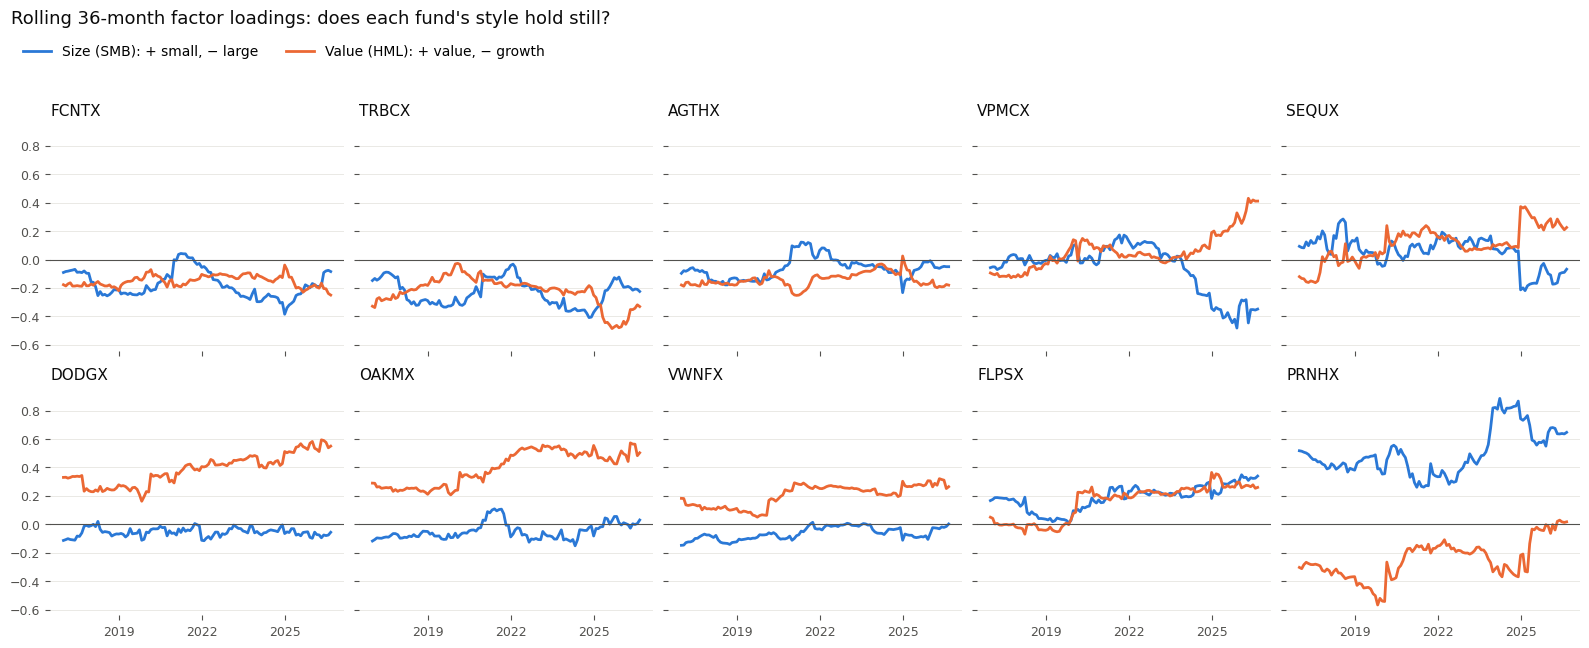

In [13]:
import matplotlib.dates as mdates

SERIES = {"SMB": ("#2a78d6", "Size (SMB): + small, − large"),
          "HML": ("#eb6834", "Value (HML): + value, − growth")}
TEXT, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e1"

fig, axes = plt.subplots(2, 5, figsize=(16, 6.5), sharex=True, sharey=True)
for ax, t in zip(axes.flat, FUNDS["ticker"]):
    d = rolling.loc[t]
    x = pd.PeriodIndex(d.index, freq="M").to_timestamp()
    for factor, (colour, label) in SERIES.items():
        ax.plot(x, d[factor], color=colour, linewidth=2, label=label)
    ax.axhline(0, color=MUTED, linewidth=0.8)
    ax.set_title(t, loc="left", fontsize=11, color=TEXT)
    ax.grid(axis="y", color=GRID, linewidth=0.6)
    ax.tick_params(colors=MUTED, labelsize=9)
    ax.xaxis.set_major_locator(mdates.YearLocator(3))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    for spine in ax.spines.values():
        spine.set_visible(False)
for ax in list(axes.flat)[len(FUNDS):]:
    ax.set_visible(False)

handles, labels = axes.flat[0].get_legend_handles_labels()
fig.suptitle("Rolling 36-month factor loadings: does each fund's style hold still?",
             x=0.01, y=0.99, ha="left", fontsize=13, color=TEXT)
fig.legend(handles, labels, loc="upper left", bbox_to_anchor=(0.01, 0.955),
           frameon=False, ncol=2, fontsize=10)
fig.tight_layout(rect=(0, 0, 1, 0.92))
fig.savefig(OUT / "rolling_loadings.png", dpi=200, bbox_inches="tight")
plt.show()

### Step 7: measured style and drift

Each fund takes the style box of the index ETF it sits closest to in (size loading, value loading) space. The reference points come from the calibration table, so there are no hand-set cut-offs. My first version used round-number thresholds, and four of the ten labels sat within 0.01 of one; this replaces it.

Where the two nearest boxes are almost equally close (within 0.05), the label is marked **borderline** on whichever dimension differs, and Part 3 treats a mismatch on that dimension with caution. Two drift measures come from the rolling loadings: range and standard deviation.

In [14]:
STYLE_BOX = {
    "IVV": ("large", "blend"), "IWF": ("large", "growth"), "IWD": ("large", "value"),
    "IWR": ("mid", "blend"),   "IWP": ("mid", "growth"),   "IWS": ("mid", "value"),
    "IWM": ("small", "blend"), "IWO": ("small", "growth"), "IWN": ("small", "value"),
}
BORDERLINE_MARGIN = 0.05

ref = calibration.loc[list(STYLE_BOX), ["load_SMB", "load_HML"]].astype(float)


def nearest_box(smb, hml):
    dist = np.sqrt((ref["load_SMB"] - smb) ** 2 + (ref["load_HML"] - hml) ** 2).sort_values()
    first, second = dist.index[0], dist.index[1]
    margin = dist.iloc[1] - dist.iloc[0]
    close_call = margin < BORDERLINE_MARGIN
    return pd.Series({
        "measured_size": STYLE_BOX[first][0],
        "measured_style": STYLE_BOX[first][1],
        "nearest_etf": first,
        "distance": dist.iloc[0],
        "runner_up_etf": second,
        "margin": margin,
        "size_borderline": close_call and STYLE_BOX[second][0] != STYLE_BOX[first][0],
        "style_borderline": close_call and STYLE_BOX[second][1] != STYLE_BOX[first][1],
    })


drift = rolling.groupby(level="ticker").agg(
    hml_range=("HML", lambda s: s.max() - s.min()),
    hml_std=("HML", "std"),
    smb_range=("SMB", lambda s: s.max() - s.min()),
    smb_std=("SMB", "std"),
)
boxes = scorecard.apply(lambda r: nearest_box(r["load_SMB"], r["load_HML"]), axis=1)

measured = (
    scorecard[["name", "load_SMB", "load_HML", "ff_r2"]]
    .join(boxes)
    .join(drift)
    .join(FUNDS.set_index("ticker")["selection_bucket"])
)
measured.to_csv(OUT / "measured_style.csv")
measured[["name", "load_SMB", "load_HML", "measured_size", "measured_style", "nearest_etf",
          "distance", "runner_up_etf", "margin", "size_borderline", "style_borderline", "selection_bucket"]]

,name,load_SMB,load_HML,measured_size,measured_style,nearest_etf,distance,runner_up_etf,margin,size_borderline,style_borderline,selection_bucket
ticker,,,,,,,,,,,,
FCNTX,Fidelity Contrafund,-0.129559,-0.138752,large,growth,IWF,0.105179,IVV,0.051171,False,False,large growth
TRBCX,T. Rowe Price Blue Chip Growth,-0.197900,-0.249368,large,growth,IWF,0.033120,IVV,0.245977,False,False,large growth
AGTHX,American Funds Growth Fund of America,-0.053348,-0.138744,large,growth,IWF,0.150359,IVV,0.016617,False,True,large growth
VPMCX,Vanguard PRIMECAP,-0.118167,0.109657,large,blend,IVV,0.092927,IWD,0.157099,False,False,large blend
SEQUX,Sequoia Fund,0.104927,0.061738,mid,blend,IWR,0.204545,IVV,0.018952,True,False,"large blend, concentrated"
DODGX,Dodge & Cox Stock,0.040396,0.373849,large,value,IWD,0.084296,IWS,0.179249,False,False,large value
OAKMX,Oakmark Fund,0.094097,0.371547,large,value,IWD,0.090121,IWS,0.122827,False,False,large value
VWNFX,Vanguard Windsor II,-0.003733,0.200169,large,value,IWD,0.107523,IVV,0.106432,False,False,large value
FLPSX,Fidelity Low-Priced Stock,0.253314,0.204107,mid,value,IWS,0.086385,IWR,0.027395,False,True,small/mid value


## Limitations

- **Survivorship bias.** Every fund here still exists today. Funds that closed after poor results are invisible, which flatters the group.
- **Mutual funds are not separately managed accounts.** A pension plan sees holdings-level data from its managers; this uses public returns only.
- **Style labels are relative to index ETFs.** A fund far from every reference point (a large distance in Step 7) doesn't fit the grid well, whatever its label says.
- **Returns-based analysis lags.** A 36-month window needs time to register a change in style, and holdings-based analysis would catch it sooner.
- **Benchmark proxies.** ETFs carry small fees and tracking differences against the indices they follow.
- **US factors only.** A fund holding foreign stocks will show a lower R², which is information, but the loadings say nothing about that foreign exposure.

## Part 1 findings

- **No manager shows skill that can be told apart from noise.** Six of the ten beat their benchmark ETF on raw return, but none has a statistically significant six-factor alpha: the largest t-statistic in absolute value is 1.41, and it belongs to a negative alpha. Return differences come from style exposures.
- **The benchmark changes the verdict.** Fidelity Contrafund trailed the Russell 1000 Growth ETF by 0.5 points a year but beat the S&P 500, the index its prospectus names, by 1.7 points a year.
- **Fidelity Low-Priced Stock behaves like a mid-cap value fund.** Its size loading (0.25) is far below the small-cap value ETF's (0.84); its beta to that ETF is 0.66 and its tracking error 9.2%, the highest in the sample.
- **Sequoia is the outlier.** It trailed the S&P 500 by 5.5 points a year, captured 108% of the index's losses in down months but 85% of its gains in up months, and has the lowest R² (0.74).
- **The value managers do what they say.** Dodge & Cox Stock and Oakmark load more heavily on value than the Russell 1000 Value ETF (0.37 against 0.29), with t-statistics of 7.5 and 6.7.

# Part 2: the stated mandate, extracted by LLM with controls

Each fund's prospectus says what the fund is allowed and intended to do. Reading ten of them by hand is slow; an LLM can do it in minutes, but only output that can be checked belongs in a due-diligence file. The controls:

1. **Fixed fields with allowed values.** The model fills a schema; it can't invent categories.
2. **Evidence for every value.** Each answer comes with a word-for-word quote, and the code checks that the quote exists in the document. This catches fabricated support. It can't tell whether a real quote supports the answer, which is what step 5 is for.
3. **"Not stated" over guessing.** The prompt forbids inferring style from a fund's name or holdings.
4. **Two models from different providers.** Their mistakes are less likely to coincide, so disagreement marks the values to look at first.
5. **Human verification of every value**, prioritised by disagreement and failed evidence checks. Each model's accuracy is measured against the verified values, along with how many errors the automatic checks caught.
6. **Required fields.** Every prospectus states its objective, expenses, turnover and benchmark, so "not stated" on any of those is treated as a failure. This catches an unreadable document, which would otherwise look like two models agreeing.
7. **Audit trail.** Every raw response is saved with the model name, a hash of the document and a timestamp, and reused on reruns, so results don't change between runs.

**To rerun this part:** add a Gemini API key to Colab Secrets as `GEMINI_API_KEY`, and upload each fund's prospectus, named by ticker, when asked. A saved `outputs.zip` from an earlier run restores the model answers, so nothing is sent to the models twice.

In [ ]:
!pip -q install google-genai anthropic pypdf

In [ ]:
import hashlib
import html
import json
import os
import re
import time
from datetime import datetime, timezone

from pypdf import PdfReader

DOCS = Path("prospectuses")   # TICKER.pdf files go here
DOCS.mkdir(exist_ok=True)
CACHE = OUT / "extractions"   # every raw model response, kept for audit
CACHE.mkdir(exist_ok=True)

# Two Gemini models of different sizes, both on the free tier. A model from a second
# provider, such as ("anthropic", "claude-haiku-5-5"), would make the cross-check more independent.
MODEL_A = ("gemini", "gemini-3.6-flash")
MODEL_B = ("gemini", "gemini-3.1-flash-lite")

# Restore saved model answers (and a completed verification file) from an earlier run.
SAVED = Path("outputs.zip")
if SAVED.exists():
    with zipfile.ZipFile(SAVED) as z:
        wanted = [n for n in z.namelist()
                  if (n.startswith("extractions/") or n.startswith("verification_completed"))
                  and not n.endswith("/") and not (OUT / n).exists()]
        for n in wanted:
            z.extract(n, OUT)
    print(f"Restored {len(wanted)} saved files from outputs.zip")

In [ ]:
def find_documents():
    found = {}
    for path in DOCS.iterdir():
        if path.suffix.lower() in (".pdf", ".htm", ".html", ".txt"):
            found[path.stem.upper()] = path
    return found


needed = [t for t in FUNDS["ticker"] if t not in find_documents()]
if needed:
    print(f"Missing prospectuses for {needed}.")
    try:
        from google.colab import files as colab_files
        print("Choose the files to upload (named by ticker):")
        for name, data in colab_files.upload().items():
            (DOCS / name).write_bytes(data)
    except ImportError:
        pass


def document_text(path):
    if path.suffix.lower() == ".pdf":
        pages = [page.extract_text() or "" for page in PdfReader(path).pages]
        return "\n\n".join(f"[page {i}]\n{text}" for i, text in enumerate(pages, 1))
    raw = path.read_text(errors="ignore")
    if path.suffix.lower() in (".htm", ".html"):
        raw = re.sub(r"(?is)<(script|style).*?</\1>", " ", raw)
        raw = re.sub(r"<[^>]+>", " ", raw)
    return html.unescape(raw)


paths = find_documents()
missing_docs = [t for t in FUNDS["ticker"] if t not in paths]
if missing_docs:
    raise FileNotFoundError(f"No prospectus for {missing_docs}. Upload TICKER.pdf files to {DOCS}/ and rerun.")

docs = {t: document_text(paths[t]) for t in FUNDS["ticker"]}
for t, text in docs.items():
    note = "  <- very little text: is this a scanned PDF?" if len(text) < 3000 else ""
    print(f"{t}: {len(text):,} characters from {paths[t].name}{note}")

### The schema and the prompt

Since 2024, SEC rules require the performance table to compare a fund with a **broad-based** market index, and many active funds add a second, style-matched index. Both are extracted, because the second is usually the fairer benchmark.

In [ ]:
FIELDS = {
    "investment_objective": "The fund's investment objective, as stated, in one sentence.",
    "market_cap_focus": "One of: large, mid, small, multi-cap, not stated. Use only an explicit statement about the size of companies the fund invests in.",
    "style_focus": "One of: growth, value, blend, not stated. Use blend only if the document says the fund invests in both growth and value stocks, or describes itself as core.",
    "geographic_scope": "One of: US only, mainly US with foreign allowed, global, not stated.",
    "max_foreign_pct": "The maximum percentage of assets that may be invested in foreign securities, as a number. null if no limit is stated.",
    "broad_based_index": "The broad-based securities market index in the performance table.",
    "additional_index": "Any additional index in the performance table, or not stated.",
    "expense_ratio_pct": "Total annual fund operating expenses for the share class with this ticker, after any fee waiver, as a number in percent.",
    "turnover_pct": "Portfolio turnover rate for the most recent fiscal year, as a number in percent.",
}
NUMERIC = {"max_foreign_pct", "expense_ratio_pct", "turnover_pct"}

PROMPT = '''You are extracting facts from a mutual fund prospectus for an investment due-diligence file.
The fund's ticker is {ticker}. Use only the document below, not outside knowledge.

For each field, return an object with:
  "value": the answer, following the field's instructions
  "evidence": a quote copied word for word from the document that supports the value (at most 40 words, no ellipses)

If the document does not state something, use "not stated" (or null for numbers) and an empty evidence string.
Do not infer size or style from the fund's name or its holdings; use explicit statements only.

Fields:
{fields}

Return only JSON in this shape, with no other text:
{{"fields": {{"<field name>": {{"value": ..., "evidence": "..."}}}}}}

DOCUMENT:
{document}
'''

FIELD_LIST = "\n".join(f"- {name}: {rule}" for name, rule in FIELDS.items())

In [ ]:
def get_secret(name):
    # Read each key from Colab Secrets once and reuse it: the secrets service can stop answering mid-run.
    if not os.environ.get(name):
        try:
            from google.colab import userdata
            os.environ[name] = userdata.get(name)
        except Exception:
            pass
    return os.environ.get(name)


def call_model(provider, model, prompt):
    if provider == "gemini":
        from google import genai
        client = genai.Client(api_key=get_secret("GEMINI_API_KEY"))
        return client.models.generate_content(model=model, contents=prompt).text
    if provider == "anthropic":
        import anthropic
        client = anthropic.Anthropic(api_key=get_secret("ANTHROPIC_API_KEY"))
        message = client.messages.create(
            model=model, max_tokens=4000, messages=[{"role": "user", "content": prompt}]
        )
        return "".join(block.text for block in message.content if block.type == "text")
    raise ValueError(f"Unknown provider: {provider}")


def parse_json(text):
    text = re.sub(r"^```(?:json)?|```$", "", text.strip()).strip()
    return json.loads(text[text.find("{"): text.rfind("}") + 1])


# Errors that retrying won't fix: stop at once with a clear message.
FATAL = ("api key", "api_key", "authentication", "unauthorized", "permission", "not found", "invalid model")
# A daily quota resets only the next day, and every retry would use more of it.
DAILY_LIMIT = ("per day", "perday")


class DailyLimitReached(RuntimeError):
    pass


def extract(ticker, provider, model, retries=3):
    doc = docs[ticker]
    doc_hash = hashlib.sha256(doc.encode()).hexdigest()[:16]
    path = CACHE / f"{ticker}__{re.sub(r'[^A-Za-z0-9._-]', '_', model)}.json"
    if path.exists():
        cached = json.loads(path.read_text())
        if cached["doc_sha256"] == doc_hash:
            return cached["parsed"]

    prompt = PROMPT.format(ticker=ticker, fields=FIELD_LIST, document=doc)
    last_error = None
    for attempt in range(retries):
        try:
            raw = call_model(provider, model, prompt)
            data = parse_json(raw)
            parsed = data.get("fields", data)
            break
        except Exception as exc:
            last_error = exc
            message = str(exc).lower()
            if any(word in message for word in DAILY_LIMIT):
                raise DailyLimitReached(f"{model} has reached its daily free-tier limit.") from exc
            if isinstance(exc, ImportError) or any(word in message for word in FATAL):
                raise RuntimeError(f"{model}: {exc}. Check the key in Colab Secrets and the model name.") from exc
            time.sleep(15 * (attempt + 1))
    else:
        raise RuntimeError(f"{ticker} / {model} failed after {retries} tries: {last_error}")

    path.write_text(json.dumps({
        "ticker": ticker,
        "provider": provider,
        "model": model,
        "doc_sha256": doc_hash,
        "timestamp_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
        "raw_response": raw,
        "parsed": parsed,
    }, indent=2))
    return parsed

In [ ]:
# Model B first, then Model A. A fund that fails on a busy server is skipped and retried
# in a later pass; a daily limit stops that model at once. Finished answers are always saved.
results, missing = {}, []
for label, (provider, model) in [("B", MODEL_B), ("A", MODEL_A)]:
    pending = list(FUNDS["ticker"])
    for attempt in range(3):
        still_failing, out_of_quota = [], False
        for i, t in enumerate(pending):
            cache_file = CACHE / f"{t}__{re.sub(r'[^A-Za-z0-9._-]', '_', model)}.json"
            was_cached = cache_file.exists()
            try:
                results[(t, label)] = extract(t, provider, model, retries=2)
            except DailyLimitReached as exc:
                print(f"  {exc} Stopping model {label}; the remaining funds wait for tomorrow's allowance.")
                still_failing += pending[i:]
                out_of_quota = True
                break
            except Exception as exc:
                print(f"  {label} {t} failed: {str(exc)[:80]}")
                still_failing.append(t)
            if not was_cached:
                time.sleep(40)  # stay under the per-minute limits
        pending = still_failing
        if not pending or out_of_quota:
            break
        print(f"Model {label}: retrying {pending} in 2 minutes")
        time.sleep(120)
    print(f"Model {label} ({model}): {len(FUNDS) - len(pending)} of {len(FUNDS)} funds done")
    missing += [(t, label) for t in pending]

if missing:
    # Save progress before stopping, so a reset Colab session doesn't lose the finished answers.
    import shutil
    shutil.make_archive("outputs", "zip", OUT)
    try:
        from google.colab import files
        files.download("outputs.zip")
    except ImportError:
        pass
    raise RuntimeError(f"Not finished yet: {missing}. Progress is saved in outputs.zip; "
                       "upload it and run again later.")

### Evidence checks and agreement

A quote counts as found if at least 80% of it appears in the document, measured two ways: by four-word sequences, and by 20-character sequences with all spaces and punctuation removed. The second matters because PDF text extraction is unreliable. Two of the Vanguard prospectuses came out with no spaces between words, and a word-based check alone failed every correctly spaced quote from them. A required field (objective, expense ratio, turnover, broad-based index) answered "not stated" also fails. Numbers agree within a tolerance (0.005 points for expense ratios, 1 point for turnover). Objectives agree if they share most of their words, and index names are compared without filler words like "Index".

In [ ]:
def norm(s):
    s = str(s).lower()
    s = re.sub(r"\[page \d+\]", " ", s)
    s = s.replace("’", "'").replace("‘", "'").replace("“", '"').replace("”", '"')
    s = re.sub(r"[‐-―-]", " ", s)
    s = re.sub(r"[^a-z0-9%.$' ]", " ", s)
    s = re.sub(r"(?<!\d)\.|\.(?!\d)", " ", s)  # drop full stops, keep decimal points
    return re.sub(r"\s+", " ", s).strip()


def shingles(tokens, n=4):
    return {tuple(tokens[i:i + n]) for i in range(len(tokens) - n + 1)}


DOC_NORM = {t: norm(text) for t, text in docs.items()}
DOC_SHINGLES = {t: shingles(text.split()) for t, text in DOC_NORM.items()}


def squash(s):
    # Letters and digits only: immune to lost spaces, line breaks and odd punctuation.
    return re.sub(r"[^a-z0-9]", "", norm(s))


def char_grams(s, n=20):
    return {s[i:i + n] for i in range(len(s) - n + 1)}


DOC_SQUASH = {t: squash(text) for t, text in docs.items()}
DOC_GRAMS = {t: char_grams(text) for t, text in DOC_SQUASH.items()}


def evidence_match(ticker, evidence):
    tokens = norm(evidence or "").split()
    if not tokens:
        return np.nan
    if len(tokens) < 4:
        word_score = float(" ".join(tokens) in DOC_NORM[ticker])
    else:
        ev = shingles(tokens)
        word_score = len(ev & DOC_SHINGLES[ticker]) / len(ev)
    sq = squash(evidence)
    if len(sq) < 20:
        char_score = float(bool(sq) and sq in DOC_SQUASH[ticker])
    else:
        grams = char_grams(sq)
        char_score = len(grams & DOC_GRAMS[ticker]) / len(grams)
    return max(word_score, char_score)


REQUIRED = {"investment_objective", "expense_ratio_pct", "turnover_pct", "broad_based_index"}


def clean(value):
    if value is None or str(value).strip().lower() in ("", "null", "none", "n/a", "not stated"):
        return "not stated"
    return value


def to_number(value):
    if value == "not stated":
        return None
    if isinstance(value, (int, float)):
        return float(value)
    m = re.search(r"-?\d+(?:\.\d+)?", str(value).replace(",", ""))
    return float(m.group()) if m else None


def norm_index(value):
    s = re.sub(r"\b(the|index|total|return|usd|tr)\b", " ", norm(value))
    return re.sub(r"\s+", " ", s).strip()


def jaccard(a, b):
    a, b = set(norm(a).split()), set(norm(b).split())
    return len(a & b) / len(a | b) if a | b else 1.0


TOLERANCE = {"expense_ratio_pct": 0.005, "turnover_pct": 1.0, "max_foreign_pct": 0.5}


def agree(field, a, b):
    if field in NUMERIC:
        a, b = to_number(a), to_number(b)
        if a is None or b is None:
            return a is None and b is None
        return abs(a - b) <= TOLERANCE[field] + 1e-9
    if field == "investment_objective":
        return jaccard(a, b) >= 0.6
    if field in ("broad_based_index", "additional_index"):
        return norm_index(a) == norm_index(b)
    return norm(a) == norm(b)


def unpack(item):
    return item if isinstance(item, dict) else {"value": item, "evidence": ""}


rows = []
for t in FUNDS["ticker"]:
    for field in FIELDS:
        a = unpack(results[(t, "A")].get(field))
        b = unpack(results[(t, "B")].get(field))
        row = {"ticker": t, "field": field}
        for label, item in (("A", a), ("B", b)):
            value = clean(item.get("value"))
            evidence = item.get("evidence") or ""
            match = evidence_match(t, evidence)
            row[f"value_{label}"] = value
            row[f"evidence_{label}"] = evidence
            row[f"evidence_match_{label}"] = match
            # A stated value needs evidence found in the document; a required field can't be "not stated".
            if value == "not stated":
                row[f"evidence_ok_{label}"] = field not in REQUIRED
            else:
                row[f"evidence_ok_{label}"] = bool(match == match and match >= 0.8)
        row["models_agree"] = agree(field, row["value_A"], row["value_B"])
        rows.append(row)

ext = pd.DataFrame(rows)
ext["priority"] = np.select(
    [~ext["models_agree"], ~(ext["evidence_ok_A"] & ext["evidence_ok_B"])], [1, 2], default=3
)
ext.to_csv(OUT / "extraction_comparison.csv", index=False)

missing_required = ext[ext["field"].isin(REQUIRED) & (ext["value_A"] == "not stated") & (ext["value_B"] == "not stated")]
for t, n in missing_required.groupby("ticker").size().items():
    print(f"WARNING {t}: both models found {n} required fields 'not stated'. Is the document readable?")

print(f"Field values compared: {len(ext)}")
print(f"Models agree: {ext['models_agree'].mean():.0%}")
print(f"Evidence found, model A: {ext['evidence_ok_A'].mean():.0%}   model B: {ext['evidence_ok_B'].mean():.0%}")
ext.groupby("field")[["models_agree", "evidence_ok_A", "evidence_ok_B"]].mean().style.format("{:.0%}")

### Human verification

The next cell writes `outputs/verification_workbook.xlsx`, listing every extracted value with disagreements first (priority 1), then failed evidence checks (2), then the rest (3). Each value is checked by hand against the prospectus and marked `A`, `B`, `both` or `neither`, with the right value recorded where neither model had it. The completed workbook, `verification_completed.xlsx`, is read back in the cell after, which measures each model's accuracy and how many of their errors the automatic checks caught. Without it, Part 3 runs on unverified values and says so.

In [ ]:
from openpyxl import Workbook
from openpyxl.styles import Alignment, Font, PatternFill
from openpyxl.worksheet.datavalidation import DataValidation

FIELD_RULES = {
    "investment_objective": "The objective as stated, in one sentence.",
    "market_cap_focus": "large / mid / small only if the strategy explicitly names that size; multi-cap if it says any size; otherwise not stated.",
    "style_focus": "growth or value only if stated; blend if it says both, or core; otherwise not stated. Not from the fund's name.",
    "geographic_scope": "US only; mainly US with foreign allowed; global (US and non-US on equal terms); or not stated.",
    "max_foreign_pct": "The stated limit on foreign securities, as a number. Blank or not stated if no limit.",
    "broad_based_index": "The broad market index in the performance table (usually the first index listed).",
    "additional_index": "Any other index in the performance table.",
    "expense_ratio_pct": "Total annual fund operating expenses for this ticker's share class, after waivers.",
    "turnover_pct": "Portfolio turnover for the most recent fiscal year.",
}
PRIORITY_LABEL = {1: "1 Models disagree", 2: "2 Evidence check failed", 3: "3 Confirm"}

FONT = "Arial"
bold = Font(name=FONT, bold=True)
plain = Font(name=FONT)
wrap = Alignment(wrap_text=True, vertical="top")
input_fill = PatternFill("solid", fgColor="FFFF00")
priority_fill = {1: PatternFill("solid", fgColor="F8CBAD"), 2: PatternFill("solid", fgColor="DDEBF7")}

wb = Workbook()
guide = wb.active
guide.title = "How to verify"
lines = [
    ("How to verify the extracted values", bold),
    ("Edit only the yellow cells on the Verify tab: verified, correct_value and notes.", plain),
    ("1. Work top to bottom. Priority 1 rows (models disagree) and 2 (evidence check failed) need a careful look; priority 3 rows need a quick confirmation.", plain),
    ("2. Open the fund's prospectus PDF and press Ctrl+F with a few words from the quote. Read the sentence around it.", plain),
    ("3. Decide whether each model's value is right under the field rule in column D, then pick from the dropdown: A, B, both or neither.", plain),
    ("4. If neither is right, type the right value in correct_value (a number for numeric fields, e.g. 0.74).", plain),
    ("5. Save as verification_completed.xlsx, upload it to the outputs folder in Colab, and run the notebook again.", plain),
    ("", plain),
    ("Example of a completed row", bold),
    ("ticker: DODGX | field: turnover_pct | value_A: 12 | value_B: 12 | verified: both | correct_value: (blank) | notes: matches page 2", plain),
    ("ticker: XYZ | field: style_focus | value_A: value | value_B: blend | verified: neither | correct_value: not stated | notes: no style statement in the strategy section", plain),
    ("", plain),
    ("Field rules", bold),
]
for i, (text, font) in enumerate(lines, 1):
    guide.cell(row=i, column=1, value=text).font = font
r = len(lines) + 1
for field, rule in FIELD_RULES.items():
    guide.cell(row=r, column=1, value=field).font = bold
    guide.cell(row=r, column=2, value=rule).font = plain
    guide.cell(row=r, column=2).alignment = wrap
    r += 1
guide.column_dimensions["A"].width = 30
guide.column_dimensions["B"].width = 110

ws = wb.create_sheet("Verify")
columns = ["priority", "ticker", "field", "field_rule", "value_A", "evidence_A", "value_B", "evidence_B",
           "evidence_match_A", "evidence_match_B", "verified", "correct_value", "notes"]
widths = [22, 9, 20, 40, 24, 50, 24, 50, 10, 10, 12, 20, 30]
for j, (name, width) in enumerate(zip(columns, widths), 1):
    cell = ws.cell(row=1, column=j, value=name)
    cell.font = bold
    cell.alignment = wrap
    ws.column_dimensions[cell.column_letter].width = width

sheet = ext.sort_values(["priority", "ticker", "field"]).reset_index(drop=True)
for i, rec in sheet.iterrows():
    r = i + 2
    values = [PRIORITY_LABEL[rec["priority"]], rec["ticker"], rec["field"], FIELD_RULES[rec["field"]],
              str(rec["value_A"]), rec["evidence_A"], str(rec["value_B"]), rec["evidence_B"],
              None if pd.isna(rec["evidence_match_A"]) else round(float(rec["evidence_match_A"]), 2),
              None if pd.isna(rec["evidence_match_B"]) else round(float(rec["evidence_match_B"]), 2),
              None, None, None]
    for j, v in enumerate(values, 1):
        cell = ws.cell(row=r, column=j, value=v)
        cell.font = plain
        cell.alignment = wrap
    if rec["priority"] in priority_fill:
        ws.cell(row=r, column=1).fill = priority_fill[rec["priority"]]
    for j in (11, 12, 13):
        ws.cell(row=r, column=j).fill = input_fill

last = len(sheet) + 1
dv = DataValidation(type="list", formula1='"A,B,both,neither"', allow_blank=True)
ws.add_data_validation(dv)
dv.add(f"K2:K{last}")
ws.freeze_panes = "D2"
ws.auto_filter.ref = f"A1:M{last}"

wb.save(OUT / "verification_workbook.xlsx")
print(f"Wrote {len(sheet)} rows: {(sheet['priority'] == 1).sum()} disagreements, "
      f"{(sheet['priority'] == 2).sum()} failed evidence checks, {(sheet['priority'] == 3).sum()} to confirm.")

In [ ]:
candidates = [OUT / "verification_completed.xlsx", OUT / "verification_completed.csv"]
VERIFIED = next((c for c in candidates if c.exists()), None)
ext["verified"] = ""
ext["correct_value"] = ""

if VERIFIED is not None:
    if VERIFIED.suffix == ".xlsx":
        v = pd.read_excel(VERIFIED, sheet_name="Verify", dtype=str, keep_default_na=False)
    else:
        v = pd.read_csv(VERIFIED, keep_default_na=False, dtype=str)
    v["verified"] = v["verified"].str.strip().str.lower()
    ext = ext.drop(columns=["verified", "correct_value"]).merge(
        v[["ticker", "field", "verified", "correct_value"]], on=["ticker", "field"], how="left"
    ).fillna({"verified": "", "correct_value": ""})

    done = ext[ext["verified"].isin(["a", "b", "both", "neither"])]
    right_a = done["verified"].isin(["a", "both"])
    right_b = done["verified"].isin(["b", "both"])
    wrong = ~(right_a & right_b)
    flagged = done["priority"] < 3

    print(f"Verified {len(done)} of {len(ext)} values")
    print(f"Accuracy  model A: {right_a.mean():.0%}   model B: {right_b.mean():.0%}")
    print(f"Values where at least one model was wrong: {wrong.sum()}")
    print(f"  ...caught by disagreement or a failed evidence check: {(wrong & flagged).sum()}")
    print(f"  ...missed by both checks (found only by human review): {(wrong & ~flagged).sum()}")
    accuracy = pd.DataFrame({"model_A": right_a, "model_B": right_b, "field": done["field"]}).groupby("field").mean()
    accuracy.to_csv(OUT / "extraction_accuracy.csv")
    display(accuracy.style.format("{:.0%}"))
else:
    print("No verification file yet. Part 3 will run on unverified values, marked as unverified.")

In [ ]:
def final_value(row):
    status = row["verified"]
    if status in ("a", "both"):
        return row["value_A"], "verified"
    if status == "b":
        return row["value_B"], "verified"
    if status == "neither":
        return row["correct_value"], "verified"
    if row["models_agree"]:
        return row["value_A"], "unverified, models agree"
    return row["value_A"], "unverified, models disagree"


finals = [final_value(r) for _, r in ext.iterrows()]
ext["final_value"] = [value for value, _ in finals]
ext["status"] = [status for _, status in finals]
stated = ext.pivot(index="ticker", columns="field", values="final_value")[list(FIELDS)]
stated["all_verified"] = ext.groupby("ticker")["status"].apply(lambda s: (s == "verified").all())
stated = stated.loc[FUNDS["ticker"]]
stated.to_csv(OUT / "stated_mandate.csv")
stated

# Part 3: stated vs measured

Each check compares one statement in the prospectus with what the returns show. **The thresholds are judgement calls**, kept in one place so they can be defended and changed.

| Check | Stated (Part 2) | Measured (Part 1) | Outcome |
|---|---|---|---|
| Size | market-cap focus | nearest style box (Step 7) | one step apart is a **tilt**; large vs small is a **contradiction** |
| Style | growth / value / blend | nearest style box (Step 7) | blend on either side is a **tilt**; growth vs value is a **contradiction** |
| Explained by US factors | geographic scope | R² of the six-factor model | below 0.85 means **check**: foreign stocks or concentration could explain it |
| Benchmark | indexes in the prospectus | the ETF proxy used in Part 1 | if the proxy's index isn't named, the benchmark **differs** |
| Stability | — | range of the rolling loadings | a range above 0.5 is **unstable** |

If the measured label on that dimension was borderline, a tilt or contradiction is reported as **borderline** instead: still flagged for review, but weaker evidence. A flag is a question to put to the manager, not a verdict. The benchmark check is the exception: it tests the proxy I chose in Part 1, not the manager, so it doesn't count towards a fund's overall flag. Where it says **differs**, consider changing that fund's benchmark in the configuration cell and rerunning.

In [ ]:
SIZE_ORDER = {"large": 0, "mid": 1, "small": 2}
R2_FLOOR = 0.85
DRIFT_RANGE = 0.50
# Names an index goes by in prospectuses; compared after the same normalisation.
PROXY_INDEX = {
    "IVV": ["S&P 500", "Standard & Poor's 500"],
    "IWF": ["Russell 1000 Growth"],
    "IWD": ["Russell 1000 Value"],
    "IWN": ["Russell 2000 Value"],
    "IWO": ["Russell 2000 Growth"],
}


def size_check(stated_size, measured_size):
    s = norm(stated_size).replace(" cap", "").strip()
    if s not in SIZE_ORDER:
        return "n/a", f"stated: {stated_size}"
    gap = abs(SIZE_ORDER[s] - SIZE_ORDER[measured_size])
    outcome = ["consistent", "tilt", "contradiction"][gap]
    return outcome, f"stated {s}, measured {measured_size}"


def style_check(stated_style, measured_style):
    s = norm(stated_style)
    if s not in ("growth", "value", "blend"):
        return "n/a", f"stated: {stated_style}"
    if s == measured_style:
        outcome = "consistent"
    elif "blend" in (s, measured_style):
        outcome = "tilt"
    else:
        outcome = "contradiction"
    return outcome, f"stated {s}, measured {measured_style}"


def r2_check(scope, max_foreign, r2):
    detail = f"R² {r2:.2f}; stated scope: {scope}; foreign limit: {max_foreign}"
    return ("consistent" if r2 >= R2_FLOOR else "check"), detail


def benchmark_check(proxy, broad, additional):
    named = f"{norm_index(broad)} | {norm_index(additional)}"
    aliases = [norm_index(name) for name in PROXY_INDEX[proxy]]
    outcome = "consistent" if any(a in named for a in aliases) else "differs"
    return outcome, f"prospectus: {broad}; {additional}. Proxy: {BENCHMARKS[proxy]}"


def stability_check(hml_range, smb_range):
    worst = max(hml_range, smb_range)
    return ("unstable" if worst > DRIFT_RANGE else "consistent"), f"HML range {hml_range:.2f}, SMB range {smb_range:.2f}"


checks = []
for f in FUNDS.itertuples(index=False):
    t = f.ticker
    m, s = measured.loc[t], stated.loc[t]
    results_row = {
        "size": size_check(s["market_cap_focus"], m["measured_size"]),
        "style": style_check(s["style_focus"], m["measured_style"]),
        "us_factor_fit": r2_check(s["geographic_scope"], s["max_foreign_pct"], m["ff_r2"]),
        "benchmark": benchmark_check(f.benchmark, s["broad_based_index"], s["additional_index"]),
        "stability": stability_check(m["hml_range"], m["smb_range"]),
    }
    # A mismatch on a borderline label is weaker evidence: report it as borderline.
    for dim in ("size", "style"):
        outcome, detail = results_row[dim]
        if m[f"{dim}_borderline"] and outcome in ("tilt", "contradiction"):
            results_row[dim] = ("borderline", f"{detail}; nearly as close to {m['runner_up_etf']}")
    row = {"ticker": t, "name": f.name}
    for check, (outcome, detail) in results_row.items():
        row[check] = outcome
        row[f"{check}_detail"] = detail
    # The benchmark check tests my proxy, not the manager, so it stays out of the overall flag.
    outcomes = [o for check, (o, _) in results_row.items() if check != "benchmark"]
    row["overall"] = (
        "contradiction" if "contradiction" in outcomes
        else "review" if any(o in ("tilt", "borderline", "check", "unstable") for o in outcomes)
        else "consistent"
    )
    row["stated_values_verified"] = bool(s["all_verified"])
    checks.append(row)

comparison = pd.DataFrame(checks).set_index("ticker")
comparison.to_csv(OUT / "stated_vs_measured.csv")
comparison[["name", "size", "style", "us_factor_fit", "benchmark", "stability", "overall", "stated_values_verified"]]

In [ ]:
FLAG_COLOURS = {"consistent": ("#2a78d6", "Consistent with stated mandate"),
                "flagged": ("#eb6834", "Flagged for review")}

ref_pts = calibration[["load_HML", "load_SMB"]].astype(float)
fig, ax = plt.subplots(figsize=(10, 6.5))
ax.axhline(0, color=MUTED, linewidth=0.8)
ax.axvline(0, color=MUTED, linewidth=0.8)

for etf, row in calibration.iterrows():
    ax.scatter(row["load_HML"], row["load_SMB"], marker="D", s=70, facecolor="white",
               edgecolor=MUTED, linewidth=1.5, zorder=2)
    ax.annotate(etf, (row["load_HML"], row["load_SMB"]), xytext=(7, -10),
                textcoords="offset points", fontsize=9, color=MUTED)

for key, (colour, label) in FLAG_COLOURS.items():
    is_consistent = (comparison["overall"] == "consistent").to_numpy()
    group = comparison.index[is_consistent if key == "consistent" else ~is_consistent]
    pts = measured.loc[group]
    ax.scatter(pts["load_HML"], pts["load_SMB"], s=90, color=colour, edgecolor="white",
               linewidth=2, zorder=3, label=label)
    for t, p in pts.iterrows():
        near_etf = (np.hypot(ref_pts["load_HML"] - p["load_HML"], ref_pts["load_SMB"] - p["load_SMB"]) < 0.06).any()
        offset, align = ((-8, -14), "right") if near_etf else ((7, 5), "left")
        ax.annotate(t, (p["load_HML"], p["load_SMB"]), xytext=offset, ha=align,
                    textcoords="offset points", fontsize=10, color=TEXT)

ax.scatter([], [], marker="D", s=70, facecolor="white", edgecolor=MUTED, linewidth=1.5,
           label="Benchmark ETF (reference)")
ax.set_xlabel("Value loading (HML):  growth  ←  →  value", color=TEXT)
ax.set_ylabel("Size loading (SMB):  large  ←  →  small", color=TEXT)
ax.set_title("Measured style map: each fund against nine index ETFs that form the style box",
             loc="left", fontsize=13, color=TEXT)
ax.grid(color=GRID, linewidth=0.6)
ax.tick_params(colors=MUTED, labelsize=9)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.legend(frameon=False, fontsize=9, loc="upper left", bbox_to_anchor=(1.01, 1))
fig.tight_layout()
fig.savefig(OUT / "style_map.png", dpi=200, bbox_inches="tight")
plt.show()

## Findings from Parts 2 and 3

*Added after human verification of every extracted value.*

## Limitations of Parts 2 and 3

- **Document editions.** Growth Fund of America's current prospectus PDF has no extractable text, so its November 2024 summary prospectus from SEC EDGAR is used.
- **PDF text.** Extraction can drop spaces or scramble tables, which is why evidence is matched on characters as well as words.
- **What the evidence check proves.** It confirms that a quote exists, not that it supports the value; human verification covers that.
- **Prospectus language.** A prospectus describes what a fund may do, which is broader than what it does.
- **Model independence.** Both models are from Google, so their mistakes are more likely to coincide than with two providers.

In [ ]:
import shutil

shutil.make_archive("outputs", "zip", OUT)
try:
    from google.colab import files
    files.download("outputs.zip")
except ImportError:
    print("Saved outputs.zip")